In [2]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 
import scipy.stats as stats

In [3]:
df = pd.read_csv("df_clean2.csv")

In [4]:
df

,student_id,enrolment_date,city,course,mode,group,pre_score,attendance_pct,final_score,completed,dropped_out,score_improvement,performance_change,enrolment_month,enrolment_day,month_name
0,1,2026-06-01,Ahmedabad,JEE,Offline,treatment,52.7,55.1,74.9,1,0,22.2,Improved,6,1,June
1,2,2026-06-01,Vadodara,NEET,Offline,control,70.3,49.6,75.4,1,0,5.1,Improved,6,1,June
2,3,2026-06-01,Ahmedabad,NEET,Online,treatment,71.6,68.2,75.7,1,0,4.1,Improved,6,1,June
3,4,2026-06-01,Ahmedabad,Class 12,Offline,control,46.0,25.4,50.0,0,1,4.0,Improved,6,1,June
4,5,2026-06-01,Ahmedabad,Class 12,Online,control,69.0,75.2,65.2,1,0,-3.8,Decline,6,1,June
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7895,7896,2026-07-26,Vadodara,NEET,Online,control,26.9,55.8,46.1,0,1,19.2,Improved,7,26,July
7896,7897,2026-07-26,Rajkot,Class 12,Online,control,29.9,23.1,47.8,0,1,17.9,Improved,7,26,July
7897,7898,2026-07-26,Surat,NEET,Offline,treatment,55.9,56.0,66.0,0,1,10.1,Improved,7,26,July
7898,7899,2026-07-26,Vadodara,NEET,Online,treatment,67.1,72.1,75.8,1,0,8.7,Improved,7,26,July


In [5]:
treatment = df[
    df['group']=='treatment'
]['score_improvement'].dropna()

In [6]:
control = df[
    df['group']=='control'
]['score_improvement'].dropna()

In [7]:
print("Treatment students:", len(treatment))
print("Control students:", len(control))

Treatment students: 3867
Control students: 3850


In [8]:
t_stat, p_value = stats.ttest_ind(
    treatment,
    control,
    equal_var=False
)

print("T-Statistic:", t_stat)
print("P-Value:", p_value)

T-Statistic: 10.174355229618081
P-Value: 3.665626045337806e-24


In [9]:
alpha = 0.05

if p_value < alpha:
    print("Reject Null Hypothesis")
    print("There is a statistically significant difference.")
else:
    print("Fail to Reject Null Hypothesis")
    print("There is not enough evidence of a significant difference.")

Reject Null Hypothesis
There is a statistically significant difference.


<h2> chi-square test

In [11]:
completion_table = pd.crosstab(
    df['group'], 
    df['completed']
)
completion_table

completed,0,1
group,,
control,2488,1462
treatment,2291,1659


In [13]:
chi_stat, p_value, dof,expected = stats.chi2_contingency(
    completion_table
)
print("Chi-Square Statistic:", chi_stat)
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)

Chi-Square Statistic: 20.347377139076166
P-Value: 6.4581549938097906e-06
Degrees of Freedom: 1


In [14]:
if p_value < 0.05:
    print("Reject Null Hypothesis")
    print("Group and completion have a significant association.")
else:
    print("Fail to Reject Null Hypothesis")
    print("No significant association found.")

Reject Null Hypothesis
Group and completion have a significant association.


In [16]:
dropout_table = pd.crosstab(
    df["group"],
    df["dropped_out"]
)

dropout_table

dropped_out,0,1
group,,
control,1462,2488
treatment,1659,2291


In [17]:
chi_stat, p_value, dof, expected = stats.chi2_contingency(
    dropout_table
)
print("Chi-Square Statistic:", chi_stat)
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)

Chi-Square Statistic: 20.347377139076166
P-Value: 6.4581549938097906e-06
Degrees of Freedom: 1


In [18]:
if p_value < 0.05:
    print("Reject Null Hypothesis")
    print("Group and dropout have a significant association.")
else:
    print("Fail to Reject Null Hypothesis")
    print("No significant association found.")

Reject Null Hypothesis
Group and dropout have a significant association.


<h2>Effect Size – Cohen's d

In [22]:
treatment_mean = treatment.mean()
control_mean = control.mean()
treatment_std = treatment.std()
control_std = control.std()
print("Treatment Mean:", treatment_mean)
print("Control Mean:", control_mean)

print("Treatment SD:", treatment_std)
print("Control SD:", control_std)

Treatment Mean: 7.125889758437106
Control Mean: 5.067466568483063
Treatment SD: 8.926657523068133
Control SD: 8.845936952544758


In [23]:
import numpy as np

n1 = len(treatment)
n2 = len(control)

pooled_std = np.sqrt(
    ((n1 - 1) * treatment_std**2 +
     (n2 - 1) * control_std**2)
    / (n1 + n2 - 2)
)

print("Pooled Standard Deviation:", pooled_std)

Pooled Standard Deviation: 8.88647782515532


In [24]:
cohens_d = (treatment_mean - control_mean)/pooled_std
print("Cohen's d:", cohens_d)

Cohen's d: 0.2316354387479795


In [25]:
if abs(cohens_d) < 0.2:
    print("Negligible Effect")
elif abs(cohens_d) < 0.5:
    print("Small Effect")
elif abs(cohens_d) < 0.8:
    print("Medium Effect")
else:
    print("Large Effect") 

Small Effect


<h2>Business Impact Analysis

In [26]:
control_completion = 37.012658
treatment_completion = 42.0

absolute_difference = treatment_completion - control_completion

relative_improvement = (
    absolute_difference / control_completion
) * 100

print("Absolute Difference:", absolute_difference)
print("Relative Improvement:", relative_improvement, "%")

Absolute Difference: 4.987341999999998
Relative Improvement: 13.474692901006996 %


In [27]:
from statsmodels.stats.weightstats import DescrStatsW, CompareMeans


In [29]:
treatment_stats = DescrStatsW(treatment)  
control_stats = DescrStatsW(control)

compare = CompareMeans(treatment_stats, control_stats)
ci_low , ci_high = compare.tconfint_diff(
    usevar="unequal", 
    alpha=0.5
)
print("95% Confidence Interval:")
print("Lower Bound:", ci_low)
print("Upper Bound:", ci_high)

95% Confidence Interval:
Lower Bound: 1.9219574608399956
Upper Bound: 2.1948889190680867


In [30]:
import pandas as pd

plot_data = pd.DataFrame({
    "group": ["Control", "Treatment"],
    "mean_improvement": [
        control.mean(),
        treatment.mean()
    ]
})

plot_data

,group,mean_improvement
0,Control,5.067467
1,Treatment,7.125890


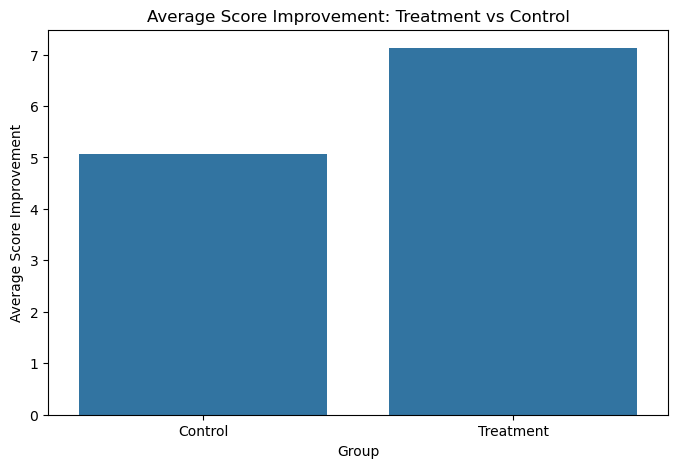

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    data=plot_data,
    x="group",
    y="mean_improvement"
)

plt.title("Average Score Improvement: Treatment vs Control")
plt.xlabel("Group")
plt.ylabel("Average Score Improvement")

plt.show()

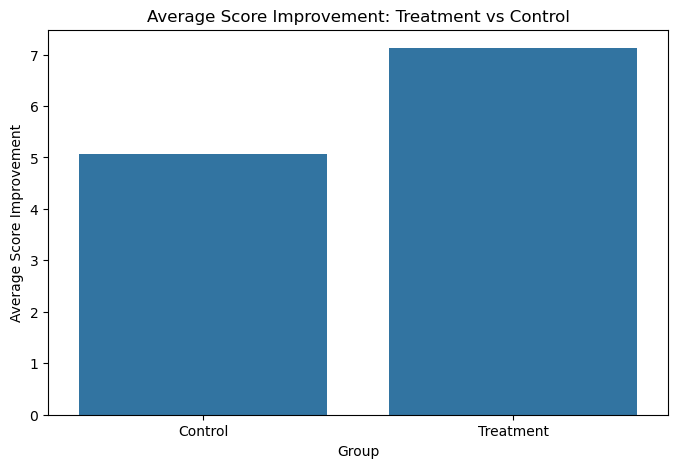

In [32]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=plot_data,
    x="group",
    y="mean_improvement"
)

plt.title("Average Score Improvement: Treatment vs Control")
plt.xlabel("Group")
plt.ylabel("Average Score Improvement")

plt.savefig(
    "score_improvement_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

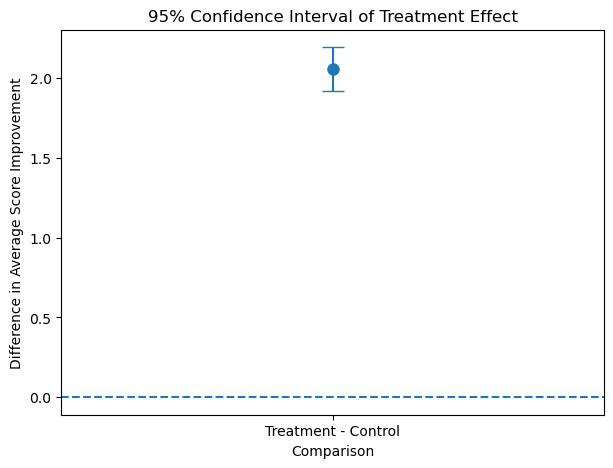

In [33]:
difference = treatment.mean() - control.mean()

ci_lower = ci_low
ci_upper = ci_high

lower_error = difference - ci_lower
upper_error = ci_upper - difference

plt.figure(figsize=(7, 5))

plt.errorbar(
    x=["Treatment - Control"],
    y=[difference],
    yerr=[[lower_error], [upper_error]],
    fmt="o",
    capsize=8,
    markersize=8
)

plt.axhline(y=0, linestyle="--")

plt.title("95% Confidence Interval of Treatment Effect")
plt.ylabel("Difference in Average Score Improvement")
plt.xlabel("Comparison")

plt.show()

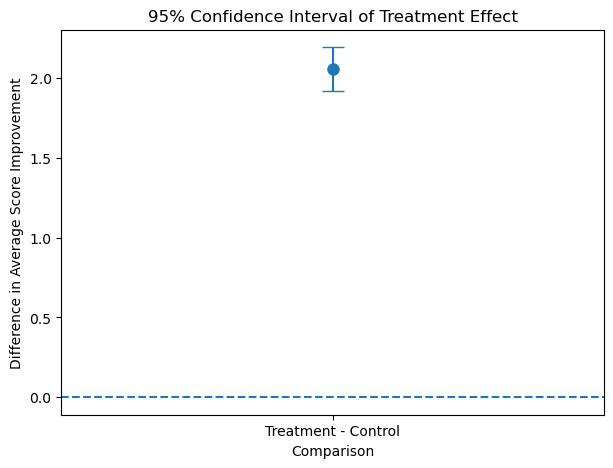

In [34]:
plt.figure(figsize=(7, 5))

plt.errorbar(
    x=["Treatment - Control"],
    y=[difference],
    yerr=[[lower_error], [upper_error]],
    fmt="o",
    capsize=8,
    markersize=8
)

plt.axhline(y=0, linestyle="--")

plt.title("95% Confidence Interval of Treatment Effect")
plt.ylabel("Difference in Average Score Improvement")
plt.xlabel("Comparison")

plt.savefig(
    "treatment_effect_confidence_interval.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
completion_data = (
    df.groupby("group")["completed"]
    .mean()
    .mul(100)
    .reset_index()
)

completion_data

,group,completed
0,control,37.012658
1,treatment,42.000000


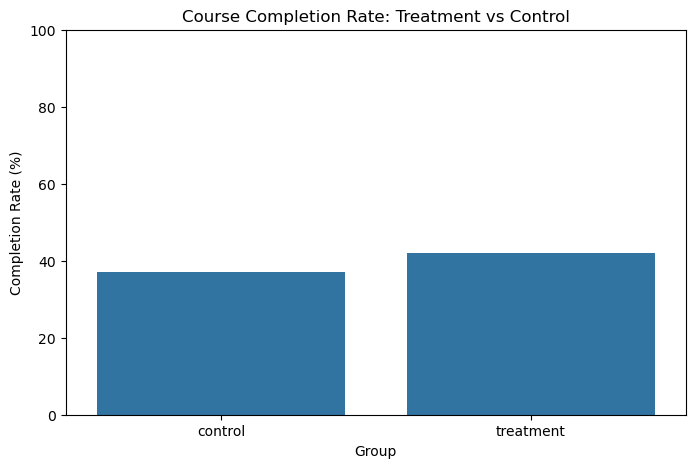

In [36]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=completion_data,
    x="group",
    y="completed"
)

plt.title("Course Completion Rate: Treatment vs Control")
plt.xlabel("Group")
plt.ylabel("Completion Rate (%)")

plt.ylim(0, 100)

plt.show()

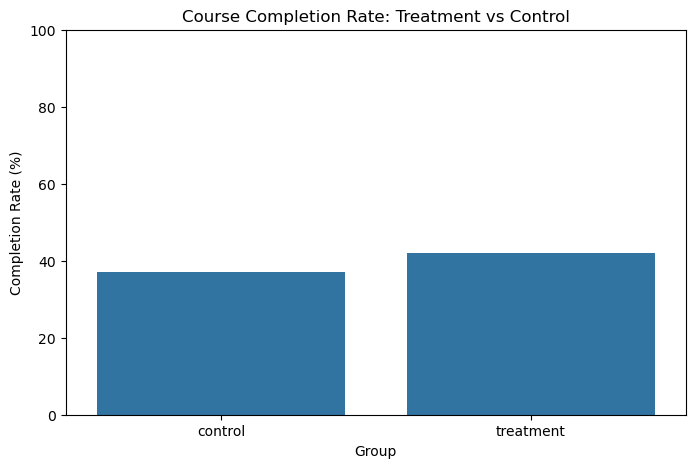

In [37]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=completion_data,
    x="group",
    y="completed"
)

plt.title("Course Completion Rate: Treatment vs Control")
plt.xlabel("Group")
plt.ylabel("Completion Rate (%)")

plt.ylim(0, 100)

plt.savefig(
    "completion_rate_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

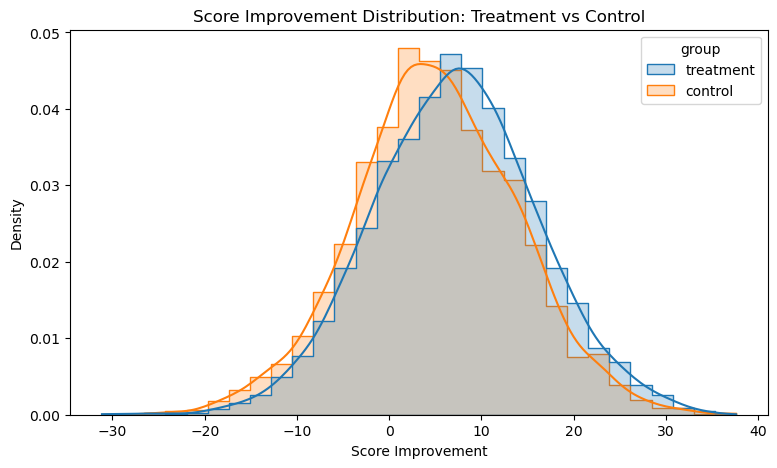

In [39]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="score_improvement",
    hue="group",
    bins=30,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Score Improvement Distribution: Treatment vs Control")
plt.xlabel("Score Improvement")
plt.ylabel("Density")

plt.show()

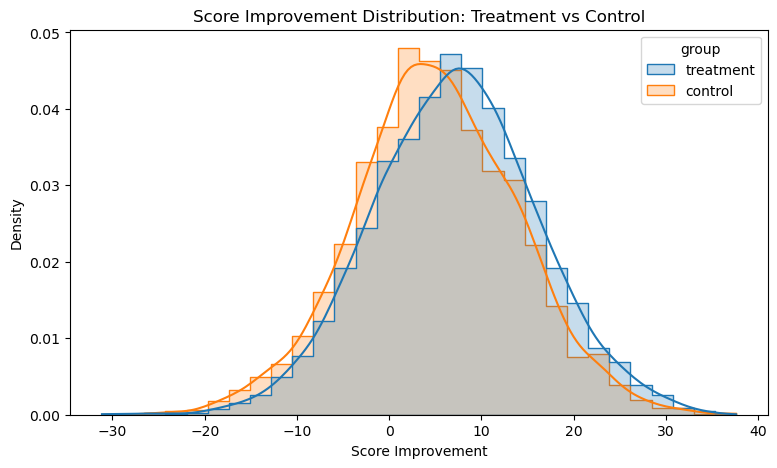

In [41]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="score_improvement",
    hue="group",
    bins=30,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Score Improvement Distribution: Treatment vs Control")
plt.xlabel("Score Improvement")
plt.ylabel("Density")

plt.savefig(
    "score_improvement_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [43]:
score_comparison = df.groupby("group").agg(
    avg_pre_score=("pre_score", "mean"),
    avg_final_score=("final_score", "mean")
).reset_index()

score_comparison

,group,avg_pre_score,avg_final_score
0,control,58.167322,63.195221
1,treatment,58.063937,65.170727


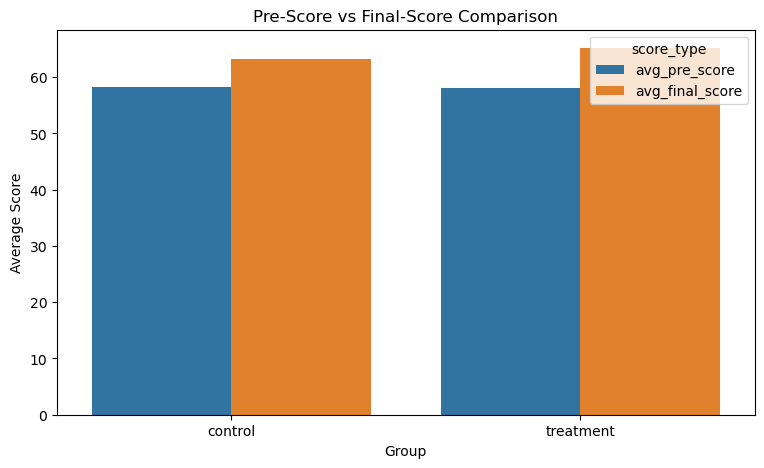

In [44]:
score_comparison_melted = score_comparison.melt(
    id_vars="group",
    value_vars=["avg_pre_score", "avg_final_score"],
    var_name="score_type",
    value_name="average_score"
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=score_comparison_melted,
    x="group",
    y="average_score",
    hue="score_type"
)

plt.title("Pre-Score vs Final-Score Comparison")
plt.xlabel("Group")
plt.ylabel("Average Score")

plt.show()

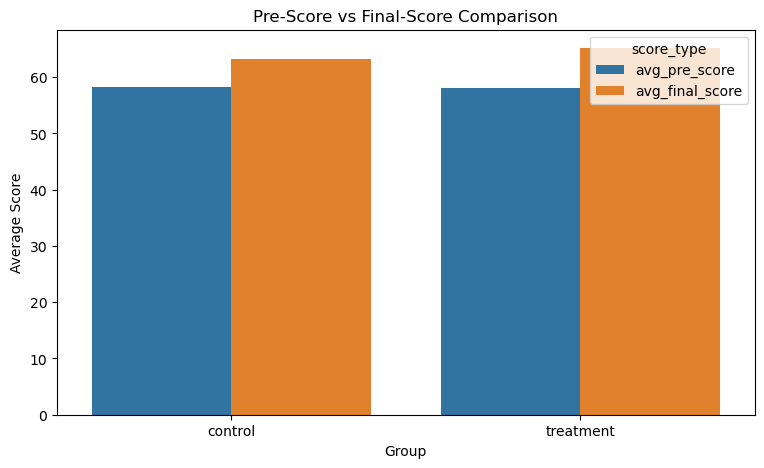

In [45]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=score_comparison_melted,
    x="group",
    y="average_score",
    hue="score_type"
)

plt.title("Pre-Score vs Final-Score Comparison")
plt.xlabel("Group")
plt.ylabel("Average Score")

plt.savefig(
    "pre_vs_final_score_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [46]:
final_results = pd.DataFrame({
    "Metric": [
        "Control Mean Improvement",
        "Treatment Mean Improvement",
        "Mean Improvement Difference",
        "Cohen's d",
        "95% CI Lower Bound",
        "95% CI Upper Bound",
        "Control Completion Rate (%)",
        "Treatment Completion Rate (%)",
        "Completion Rate Difference (pp)"
    ],

    "Value": [
        control.mean(),
        treatment.mean(),
        treatment.mean() - control.mean(),
        0.2316,
        ci_low,
        ci_high,
        37.0127,
        42.0000,
        4.9873
    ]
})

final_results

,Metric,Value
0,Control Mean Improvement,5.067467
1,Treatment Mean Improvement,7.125890
2,Mean Improvement Difference,2.058423
3,Cohen's d,0.231600
4,95% CI Lower Bound,1.921957
5,95% CI Upper Bound,2.194889
6,Control Completion Rate (%),37.012700
7,Treatment Completion Rate (%),42.000000
8,Completion Rate Difference (pp),4.987300
